# What Washington Says About AI: figures and headline numbers

Generated from `site/data/` (the same data the site shows). Re-run `uv run python analysis/build_notebook.py` after a refresh.
Scores run from 0 to 4 and are the average of two shuffled scoring runs. `insufficient_evidence` is excluded from every mean and share.

In [1]:
import json, collections, statistics, math
from pathlib import Path
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
FIG = ROOT / 'analysis/figures'; FIG.mkdir(parents=True, exist_ok=True)
M = json.loads((ROOT / 'site/data/members.json').read_text())['members']
T = json.loads((ROOT / 'site/data/timeline.json').read_text())
DIMS = ['ai_overall', 'agi_pilled', 'x_risk', 'china_race', 'regulation']
LABEL = {'ai_overall': 'AI overall', 'agi_pilled': 'AGI-pilled', 'x_risk': 'X-risk', 'china_race': 'China race', 'regulation': 'Pro-regulation'}
PC = {'D': '#3b6fd4', 'R': '#d0453b', 'I': '#8a6bbf'}
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
H = {}  # headline numbers
def sc(m, k):
    v = m['scores'].get(k); return v if isinstance(v, (int, float)) else None
cur = [m for m in M if m['status'] == 'current']
print(len(M), 'people;', len(cur), 'current')

649 people; 539 current


## Coverage

In [2]:
src = collections.Counter()
for m in M:
    for k, v in (m.get('n_by_src') or {}).items(): src[k] += v
H['people'] = len(M); H['current'] = len(cur); H['members_elect'] = len(M) - len(cur)
H['statements'] = sum(m['n'] for m in M); H['statements_by_source'] = dict(src)
H['current_with_any_ai_statement'] = sum(m['n'] > 0 for m in cur)
H['current_scored_ai_overall'] = sum(sc(m, 'ai_overall') is not None for m in cur)
H['median_statements_current'] = statistics.median(m['n'] for m in cur)
top_talkers = sorted(cur, key=lambda m: -m['n'])[:10]
H['top_talkers'] = [(m['name'], m['party'], m['n']) for m in top_talkers]
{k: H[k] for k in ['people','current','members_elect','statements','statements_by_source','current_with_any_ai_statement','current_scored_ai_overall','median_statements_current','top_talkers']}

{'people': 649,
 'current': 539,
 'members_elect': 110,
 'statements': 15481,
 'statements_by_source': {'web': 3554,
  'x': 9005,
  'hearing': 2568,
  'floor': 340,
  'official': 14},
 'current_with_any_ai_statement': 533,
 'current_scored_ai_overall': 403,
 'median_statements_current': 15,
 'top_talkers': [('Ted Lieu', 'D', 404),
  ('Josh Hawley', 'R', 293),
  ('Bernard Sanders', 'I', 265),
  ('Ro Khanna', 'D', 257),
  ('Amy Klobuchar', 'D', 243),
  ('Mark R. Warner', 'D', 215),
  ('Ted Cruz', 'R', 215),
  ('Charles E. Schumer', 'D', 185),
  ('Nancy Mace', 'R', 177),
  ('David McCormick', 'R', 172)]}

## Score distributions by party (current members)

In [3]:
rows = {}
for k in DIMS:
    for p in 'DR':
        v = [sc(m, k) for m in cur if m['party'] == p and sc(m, k) is not None]
        rows[(k, p)] = dict(n=len(v), mean=round(statistics.mean(v), 2) if v else None,
                            share_ge3=round(sum(x >= 3 for x in v) / len(v), 3) if v else None,
                            n_insufficient=sum(1 for m in cur if m['party'] == p and sc(m, k) is None))
H['by_party'] = {f'{k}_{p}': r for (k, p), r in rows.items()}
for (k, p), r in rows.items(): print(f'{LABEL[k]:15s} {p}  n={r["n"]:3d}  mean={r["mean"]}  share>=3={r["share_ge3"]}  insufficient={r["n_insufficient"]}')

AI overall      D  n=202  mean=1.75  share>=3=0.104  insufficient=60
AI overall      R  n=198  mean=2.69  share>=3=0.601  insufficient=76
AGI-pilled      D  n=249  mean=0.99  share>=3=0.06  insufficient=13
AGI-pilled      R  n=251  mean=1.1  share>=3=0.052  insufficient=23
X-risk          D  n=249  mean=1.21  share>=3=0.281  insufficient=13
X-risk          R  n=251  mean=0.52  share>=3=0.108  insufficient=23
China race      D  n=249  mean=1.11  share>=3=0.141  insufficient=13
China race      R  n=251  mean=2.36  share>=3=0.55  insufficient=23
Pro-regulation  D  n=234  mean=2.52  share>=3=0.325  insufficient=28
Pro-regulation  R  n=224  mean=1.83  share>=3=0.071  insufficient=50


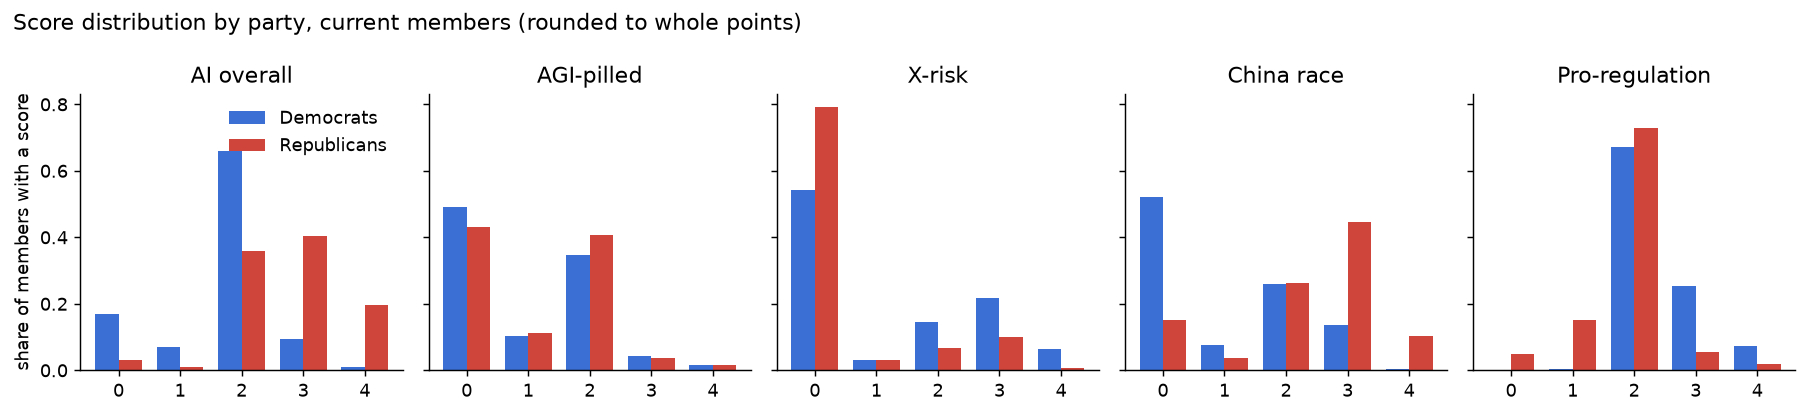

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharey=True)
for ax, k in zip(axes, DIMS):
    for i, p in enumerate('DR'):
        v = [sc(m, k) for m in cur if m['party'] == p and sc(m, k) is not None]
        bins = [0, 1, 2, 3, 4]
        cnt = [sum(1 for x in v if round(x) == b) / max(len(v), 1) for b in bins]
        ax.bar([b + (i - .5) * .38 for b in bins], cnt, width=.38, color=PC[p], label={'D': 'Democrats', 'R': 'Republicans'}[p])
    ax.set_title(LABEL[k]); ax.set_xticks(range(5))
axes[0].set_ylabel('share of members with a score'); axes[0].legend(frameon=False)
fig.suptitle('Score distribution by party, current members (rounded to whole points)', x=.01, ha='left')
fig.tight_layout(); fig.savefig(FIG / 'party_distributions.png', bbox_inches='tight')

## How many members talk about AGI and existential risk?

In [5]:
def cnt(pop, k, t): return sum(1 for m in pop if (sc(m, k) or 0) >= t)
H['current_agi_ge3'] = cnt(cur, 'agi_pilled', 3); H['current_agi_4'] = cnt(cur, 'agi_pilled', 4)
H['current_xrisk_ge3'] = cnt(cur, 'x_risk', 3); H['current_xrisk_4'] = cnt(cur, 'x_risk', 4)
H['current_xrisk_ge3_by_party'] = {p: sum(1 for m in cur if m['party'] == p and (sc(m, 'x_risk') or 0) >= 3) for p in 'DRI'}
H['current_agi_ge3_by_party'] = {p: sum(1 for m in cur if m['party'] == p and (sc(m, 'agi_pilled') or 0) >= 3) for p in 'DRI'}
H['xrisk_4_names'] = [(m['name'], m['party'], m['status']) for m in M if (sc(m, 'x_risk') or 0) >= 4]
H['agi_ge3_5_names'] = [(m['name'], m['party'], m['status']) for m in M if (sc(m, 'agi_pilled') or 0) >= 3.5]
both = [m for m in cur if (sc(m, 'agi_pilled') or 0) >= 3 and (sc(m, 'x_risk') or 0) >= 3]
H['current_agi_and_xrisk_ge3'] = len(both)
{k: H[k] for k in ['current_agi_ge3','current_agi_4','current_xrisk_ge3','current_xrisk_4','current_xrisk_ge3_by_party','current_agi_ge3_by_party','current_agi_and_xrisk_ge3','xrisk_4_names','agi_ge3_5_names']}

{'current_agi_ge3': 29,
 'current_agi_4': 3,
 'current_xrisk_ge3': 99,
 'current_xrisk_4': 11,
 'current_xrisk_ge3_by_party': {'D': 70, 'R': 27, 'I': 2},
 'current_agi_ge3_by_party': {'D': 15, 'R': 13, 'I': 1},
 'current_agi_and_xrisk_ge3': 18,
 'xrisk_4_names': [('Bernard Sanders', 'I', 'current'),
  ('Christopher A. Coons', 'D', 'current'),
  ('Michael F. Bennet', 'D', 'current'),
  ('Marc A. Veasey', 'D', 'current'),
  ('Seth Moulton', 'D', 'current'),
  ('Roger Marshall', 'R', 'current'),
  ('Clay Higgins', 'R', 'current'),
  ('Robert Garcia', 'D', 'current'),
  ('Christopher R. Deluzio', 'D', 'current'),
  ('Greg Casar', 'D', 'current'),
  ('Maxine Dexter', 'D', 'current'),
  ('Sam Forstag', 'D', 'member_elect'),
  ('Abdul El-Sayed', 'D', 'member_elect')],
 'agi_ge3_5_names': [('Marsha Blackburn', 'R', 'current'),
  ('Bill Foster', 'D', 'current'),
  ('Norma J. Torres', 'D', 'current'),
  ('Andy Biggs', 'R', 'current'),
  ('Anna Paulina Luna', 'R', 'current'),
  ('Christopher R. D

## Ideology vs. scores (GovTrack, current members)

In [6]:
def spearman(a, b):
    def rk(x):
        o = sorted(range(len(x)), key=lambda i: x[i]); r = [0.0] * len(x); i = 0
        while i < len(o):
            j = i
            while j + 1 < len(o) and x[o[j + 1]] == x[o[i]]: j += 1
            for q in range(i, j + 1): r[o[q]] = (i + j) / 2
            i = j + 1
        return r
    ra, rb = rk(a), rk(b); ma, mb = sum(ra) / len(ra), sum(rb) / len(rb)
    c = sum((x - ma) * (y - mb) for x, y in zip(ra, rb))
    return c / math.sqrt(sum((x - ma) ** 2 for x in ra) * sum((y - mb) ** 2 for y in rb))
H['ideology_spearman'] = {}
for k in DIMS:
    pr = [(m['ideology'], sc(m, k)) for m in cur if m.get('ideology') is not None and sc(m, k) is not None]
    H['ideology_spearman'][k] = dict(n=len(pr), rho=round(spearman([a for a, _ in pr], [b for _, b in pr]), 2))
H['ideology_spearman']

{'ai_overall': {'n': 400, 'rho': 0.49},
 'agi_pilled': {'n': 496, 'rho': 0.08},
 'x_risk': {'n': 496, 'rho': -0.17},
 'china_race': {'n': 496, 'rho': 0.48},
 'regulation': {'n': 454, 'rho': -0.49}}

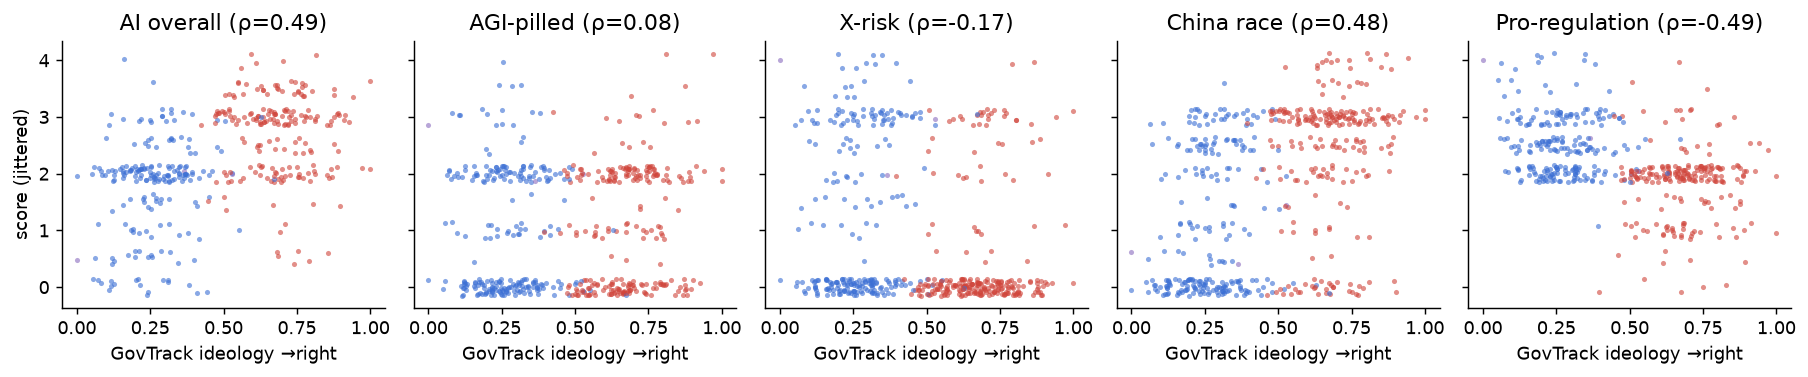

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3), sharey=True)
import random; rnd = random.Random(0)
for ax, k in zip(axes, DIMS):
    for m in cur:
        if m.get('ideology') is None or sc(m, k) is None: continue
        ax.scatter(m['ideology'], sc(m, k) + rnd.uniform(-.15, .15), s=8, color=PC.get(m['party'], '#888'), alpha=.6, lw=0)
    ax.set_title(f"{LABEL[k]} (ρ={H['ideology_spearman'][k]['rho']})"); ax.set_xlabel('GovTrack ideology →right')
axes[0].set_ylabel('score (jittered)')
fig.tight_layout(); fig.savefig(FIG / 'ideology_scatter.png', bbox_inches='tight')

## Topics over time

Statements per quarter, split evenly across each statement's topics. **Caveats:** X collection starts in 2023-01. Web research favours recent, prominent statements. Official records lag. 2026-Q4 is partial. Read the *shares* rather than the absolute counts.

In [8]:
Q = sorted({r['q'] for r in T}); TOP = sorted({r['topic'] for r in T})
tot = collections.defaultdict(float); by = collections.defaultdict(float); byp = collections.defaultdict(float); totp = collections.defaultdict(float)
for r in T:
    tot[r['q']] += r['n']; by[(r['q'], r['topic'])] += r['n']
    byp[(r['q'], r['party'], r['topic'])] += r['n']; totp[(r['q'], r['party'])] += r['n']
share = {t: [by[(q, t)] / tot[q] if tot[q] else 0 for q in Q] for t in TOP}
def yr(t, years):
    n = sum(by[(q, t)] for q in Q if q[:4] in years); d = sum(tot[q] for q in Q if q[:4] in years); return round(n / d, 3)
H['topic_share_2023_vs_2026'] = {t: (yr(t, {'2023'}), yr(t, {'2026'})) for t in TOP}
H['statements_per_year'] = {y: round(sum(tot[q] for q in Q if q.startswith(y))) for y in sorted({q[:4] for q in Q})}
H['topic_share_2023_vs_2026']

{'AGI/transformative': (0.032, 0.025),
 'China/competition': (0.053, 0.084),
 'copyright': (0.035, 0.007),
 'deepfakes/elections': (0.072, 0.031),
 'energy/data centers': (0.004, 0.102),
 'jobs/economy': (0.067, 0.114),
 'kids/online safety': (0.021, 0.033),
 'misuse (bio/cyber)': (0.028, 0.018),
 'national security': (0.091, 0.063),
 'other': (0.211, 0.164),
 'regulation': (0.279, 0.241),
 'untagged': (0.085, 0.063),
 'x-risk/loss of control': (0.022, 0.055)}

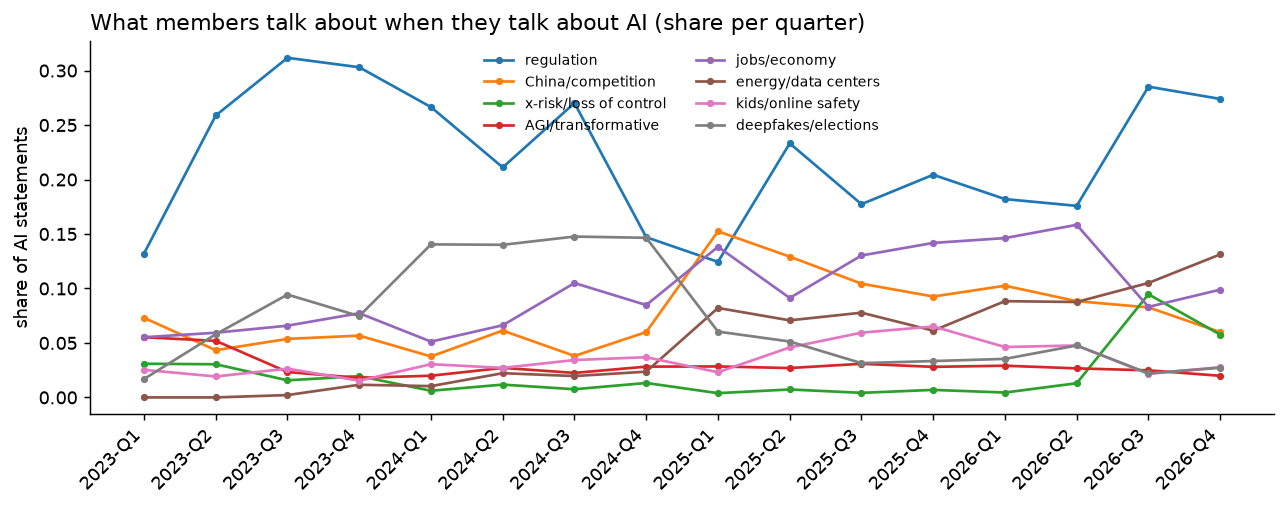

In [9]:
focus = ['regulation', 'China/competition', 'x-risk/loss of control', 'AGI/transformative', 'jobs/economy', 'energy/data centers', 'kids/online safety', 'deepfakes/elections']
fig, ax = plt.subplots(figsize=(10, 4))
for t in focus:
    if t in share: ax.plot(Q, share[t], marker='o', ms=3, label=t)
ax.set_ylabel('share of AI statements'); ax.set_xticks(range(len(Q))); ax.set_xticklabels(Q, rotation=45, ha='right')
ax.legend(frameon=False, fontsize=8, ncol=2); ax.set_title('What members talk about when they talk about AI (share per quarter)', loc='left')
fig.tight_layout(); fig.savefig(FIG / 'topic_shares.png', bbox_inches='tight')

{'D': (0.023, 0.069), 'R': (0.019, 0.028)}

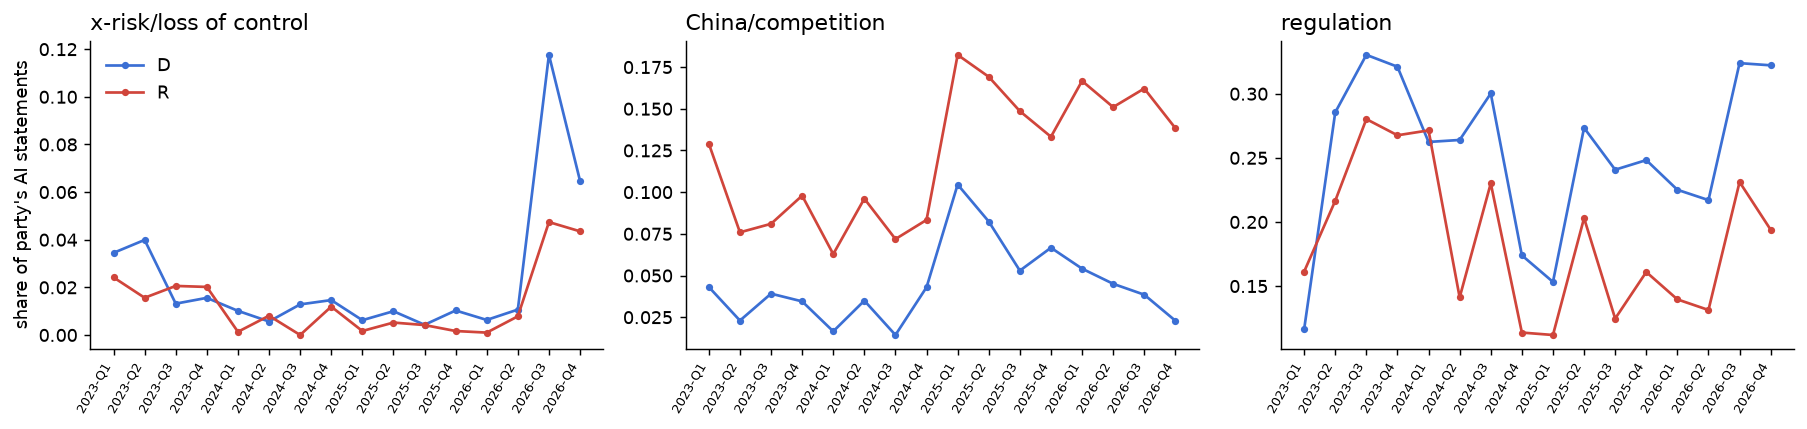

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=False)
for ax, t in zip(axes, ['x-risk/loss of control', 'China/competition', 'regulation']):
    for p in 'DR':
        ax.plot(Q, [byp[(q, p, t)] / totp[(q, p)] if totp[(q, p)] else 0 for q in Q], color=PC[p], marker='o', ms=3, label=p)
    ax.set_title(t, loc='left'); ax.set_xticks(range(len(Q))); ax.set_xticklabels(Q, rotation=60, ha='right', fontsize=7)
axes[0].set_ylabel("share of party's AI statements"); axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / 'topic_by_party.png', bbox_inches='tight')
H['xrisk_share_by_party_2023_vs_2026'] = {p: tuple(round(sum(byp[(q, p, 'x-risk/loss of control')] for q in Q if q[:4] == y) / max(sum(totp[(q, p)] for q in Q if q[:4] == y), 1), 3) for y in ('2023', '2026')) for p in 'DR'}
H['xrisk_share_by_party_2023_vs_2026']

## Members-elect vs. the current Congress

In [11]:
el = [m for m in M if m['status'] == 'member_elect']
H['elect_vs_current_mean'] = {}
for k in DIMS:
    a = [sc(m, k) for m in cur if sc(m, k) is not None]; b = [sc(m, k) for m in el if sc(m, k) is not None]
    H['elect_vs_current_mean'][k] = dict(current=round(statistics.mean(a), 2), elect=round(statistics.mean(b), 2) if b else None, n_elect=len(b))
H['elect_with_any_ai_statement'] = sum(m['n'] > 0 for m in el)
H['elect_vs_current_mean'], H['elect_with_any_ai_statement'], len(el)

({'ai_overall': {'current': 2.21, 'elect': 1.71, 'n_elect': 58},
  'agi_pilled': {'current': 1.05, 'elect': 0.52, 'n_elect': 85},
  'x_risk': {'current': 0.88, 'elect': 0.64, 'n_elect': 85},
  'china_race': {'current': 1.73, 'elect': 0.7, 'n_elect': 85},
  'regulation': {'current': 2.19, 'elect': 2.43, 'n_elect': 77}},
 102,
 110)

## Chamber

In [12]:
H['chamber_mean'] = {k: {c: round(statistics.mean([sc(m, k) for m in cur if m['chamber'] == c and sc(m, k) is not None]), 2) for c in ('house', 'senate')} for k in DIMS}
H['chamber_mean']

{'ai_overall': {'house': 2.2, 'senate': 2.24},
 'agi_pilled': {'house': 0.97, 'senate': 1.38},
 'x_risk': {'house': 0.72, 'senate': 1.5},
 'china_race': {'house': 1.61, 'senate': 2.19},
 'regulation': {'house': 2.14, 'senate': 2.35}}

## Agreement between the two scoring runs, and with Roe (Jan 2026)

In [13]:
S = json.loads((ROOT / 'data/scores.json').read_text())
agree = collections.Counter()
for v in S.values():
    for k in DIMS:
        d = (v.get('dimensions') or {}).get(k) or {}
        a, b = d.get('run_a'), d.get('run_b')
        if isinstance(a, (int, float)) and isinstance(b, (int, float)): agree[abs(a - b)] += 1
H['run_agreement'] = {str(k): v for k, v in sorted(agree.items())}
H['run_exact_agreement'] = round(agree[0] / sum(agree.values()), 3)
roe = (ROOT / 'review/roe_comparison.md').read_text()
import re; H['roe_spearman'] = dict(re.findall(r'## (\w+)\n\nn = \d+ · Spearman ρ = \*\*([-\d.]+)', roe))
H['run_agreement'], H['run_exact_agreement'], H['roe_spearman']

({'0': 2073, '1': 441, '2': 115, '3': 20, '4': 1},
 0.782,
 {'agi_pilled': '0.46', 'x_risk': '0.34', 'china_race': '0.54'})

In [14]:
(ROOT / 'analysis/headline_numbers.json').write_text(json.dumps(H, indent=1, ensure_ascii=False))
print('wrote headline_numbers.json and', len(list(FIG.glob('*.png'))), 'figures')

wrote headline_numbers.json and 4 figures
